UCS420 (Cognitive Computing) - Assignment 8

Question 1

In [1]:
import re
import nltk
import string
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial Intelligence is transforming the world.
It helps machines learn, solve problems and make decisions.
I find AI fascinating because it combines creativity and technology.
Machine learning allows computers to improve through experience.
AI has applications in healthcare, education and entertainment."""

text = text.lower()
text = re.sub(r'[^\w\s]', '', text)

print("Original Processed Text:\n", text)

words = word_tokenize(text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

split_words = text.split()

print("\nUsing split():\n", split_words)
print("\nUsing word_tokenize():\n", words)

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nWords after Stopword Removal:\n", filtered_words)

frequency = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in frequency.items():
    print(word, ":", count)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Original Processed Text:
 artificial intelligence is transforming the world
it helps machines learn solve problems and make decisions
i find ai fascinating because it combines creativity and technology
machine learning allows computers to improve through experience
ai has applications in healthcare education and entertainment

Word Tokens:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'it', 'helps', 'machines', 'learn', 'solve', 'problems', 'and', 'make', 'decisions', 'i', 'find', 'ai', 'fascinating', 'because', 'it', 'combines', 'creativity', 'and', 'technology', 'machine', 'learning', 'allows', 'computers', 'to', 'improve', 'through', 'experience', 'ai', 'has', 'applications', 'in', 'healthcare', 'education', 'and', 'entertainment']

Sentence Tokens:
 ['artificial intelligence is transforming the world\nit helps machines learn solve problems and make decisions\ni find ai fascinating because it combines creativity and technology\nmachine learning allows compute

Question 2

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial Intelligence is transforming the world.
It helps machines learn, solve problems and make decisions.
I find AI fascinating because it combines creativity and technology.
Machine learning allows computers to improve through experience.
AI has applications in healthcare, education and entertainment."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [stemmer.stem(word) for word in filtered_words]
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

print("Original Words:\n", filtered_words)
print("\nStemmed Words:\n", stemmed_words)
print("\nLemmatized Words:\n", lemmatized_words)

print("\nComparison:")
for original, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(original, "->", stem, "|", lemma)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Original Words:
 ['artificial', 'intelligence', 'transforming', 'world', 'helps', 'machines', 'learn', 'solve', 'problems', 'make', 'decisions', 'find', 'ai', 'fascinating', 'combines', 'creativity', 'technology', 'machine', 'learning', 'allows', 'computers', 'improve', 'experience', 'ai', 'applications', 'healthcare', 'education', 'entertainment']

Stemmed Words:
 ['artifici', 'intellig', 'transform', 'world', 'help', 'machin', 'learn', 'solv', 'problem', 'make', 'decis', 'find', 'ai', 'fascin', 'combin', 'creativ', 'technolog', 'machin', 'learn', 'allow', 'comput', 'improv', 'experi', 'ai', 'applic', 'healthcar', 'educ', 'entertain']

Lemmatized Words:
 ['artificial', 'intelligence', 'transforming', 'world', 'help', 'machine', 'learn', 'solve', 'problem', 'make', 'decision', 'find', 'ai', 'fascinating', 'combine', 'creativity', 'technology', 'machine', 'learning', 'allows', 'computer', 'improve', 'experience', 'ai', 'application', 'healthcare', 'education', 'entertainment']

Comparis

Question 3

In [3]:
import nltk
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps machines learn and solve complex problems.",
    "Blockchain provides secure and transparent digital transactions.",
    "Machine learning is an important application of artificial intelligence."
]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words:")
print(count_vectorizer.get_feature_names_out())
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

features = tfidf_vectorizer.get_feature_names_out()

print("\nTop 3 Keywords for Each Text:")

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray()[0]
    top_indices = scores.argsort()[-3:][::-1]

    print("\nText", i + 1, ":")
    for index in top_indices:
        print(features[index], ":", round(scores[index], 3))

Bag of Words:
['an' 'and' 'application' 'artificial' 'blockchain' 'complex' 'digital'
 'helps' 'important' 'intelligence' 'is' 'learn' 'learning' 'machine'
 'machines' 'of' 'problems' 'provides' 'secure' 'solve' 'transactions'
 'transparent']
[[0 1 0 1 0 1 0 1 0 1 0 1 0 0 1 0 1 0 0 1 0 0]
 [0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1]
 [1 0 1 1 0 0 0 0 1 1 1 0 1 1 0 1 0 0 0 0 0 0]]

TF-IDF Matrix:
[[0.         0.27345018 0.         0.27345018 0.         0.35955412
  0.         0.35955412 0.         0.27345018 0.         0.35955412
  0.         0.         0.35955412 0.         0.35955412 0.
  0.         0.35955412 0.         0.        ]
 [0.         0.29651988 0.         0.         0.38988801 0.
  0.38988801 0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.38988801
  0.38988801 0.         0.38988801 0.38988801]
 [0.35013871 0.         0.35013871 0.26628951 0.         0.
  0.         0.         0.35013871 0.26628951 0.35013871 0.
 

Question 4

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')

text1 = """
Artificial Intelligence allows machines to learn from data.
It helps computers solve problems and make decisions.
AI is used in healthcare, education and automation.
Machine learning is an important part of AI.
AI improves efficiency and reduces human effort.
"""

text2 = """
Blockchain is a decentralized digital technology.
It stores information securely across multiple computers.
Blockchain is used in cryptocurrency and digital payments.
It provides transparency and prevents data modification.
Blockchain improves security and trust in transactions.
"""

def preprocess(text):
    text = text.lower()
    words = re.findall(r'\b[a-z]+\b', text)
    stop_words = set(stopwords.words('english'))
    return [word for word in words if word not in stop_words]

words1 = preprocess(text1)
words2 = preprocess(text2)

set1 = set(words1)
set2 = set(words2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("Jaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nAnalysis:")

if cosine > jaccard:
    print("Cosine similarity gives a higher similarity score.")
else:
    print("Jaccard similarity gives a higher similarity score.")

print("Jaccard measures common unique words, while cosine similarity")
print("considers TF-IDF word importance and vector direction.")

Jaccard Similarity: 0.0909
Cosine Similarity: 0.2494

Analysis:
Cosine similarity gives a higher similarity score.
Jaccard measures common unique words, while cosine similarity
considers TF-IDF word importance and vector direction.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Question 5

In [5]:
!pip install textblob wordcloud

Sentiment Analysis Results:

Review: This product is amazing. I absolutely love its quality and performance.
Polarity: 0.55
Subjectivity: 0.75
Sentiment: Positive
--------------------------------------------------
Review: The service was excellent and the delivery was very fast.
Polarity: 0.63
Subjectivity: 0.89
Sentiment: Positive
--------------------------------------------------
Review: I am extremely disappointed. The product stopped working after two days.
Polarity: -0.75
Subjectivity: 0.75
Sentiment: Negative
--------------------------------------------------
Review: The quality is poor and customer support was terrible.
Polarity: -0.7
Subjectivity: 0.8
Sentiment: Negative
--------------------------------------------------
Review: The product is okay. It works as expected but nothing special.
Polarity: 0.25
Subjectivity: 0.49
Sentiment: Positive
--------------------------------------------------


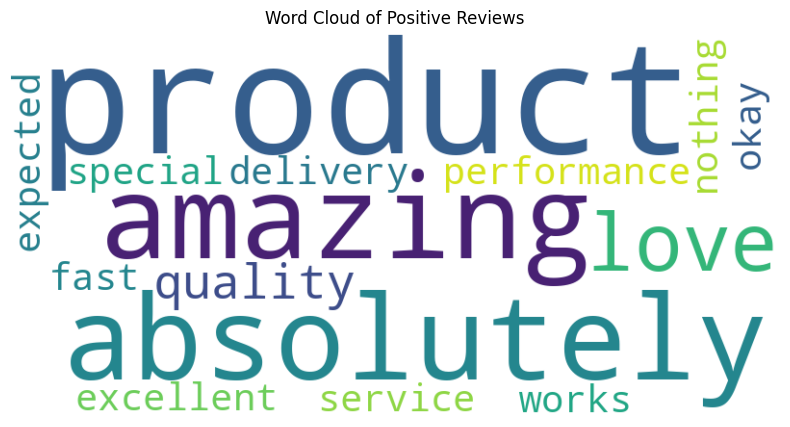

In [7]:
import nltk
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This product is amazing. I absolutely love its quality and performance.",
    "The service was excellent and the delivery was very fast.",
    "I am extremely disappointed. The product stopped working after two days.",
    "The quality is poor and customer support was terrible.",
    "The product is okay. It works as expected but nothing special."
]

positive_reviews = []

print("Sentiment Analysis Results:\n")

for review in reviews:
    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)
    print("-" * 50)

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()

Question 6

In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Artificial intelligence is changing the modern world.
Technology helps people solve problems and improve their lives.
Machine learning allows computers to learn from data and experience.
Deep learning uses neural networks to understand complex patterns.
Artificial intelligence is used in healthcare, education and business.
Computers can recognize images, understand language and make predictions.
Technology continues to develop and create new opportunities.
Students use artificial intelligence to learn programming and explore ideas.
Machine learning improves systems by analyzing information.
The future of technology depends on innovation and creativity.
Artificial intelligence makes machines smarter and more useful.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

sequences = []

for line in text.split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequences.append(token_list[:i + 1])

max_sequence_len = max(len(seq) for seq in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential([
    Embedding(total_words, 64),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=200, verbose=1)

def generate_text(seed_text, next_words):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_word_index = np.argmax(predicted)

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:\n")

print("Line 1:", generate_text("artificial", 10))
print("Line 2:", generate_text("machine learning", 10))
print("Line 3:", generate_text("technology", 10))

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.0000e+00 - loss: 4.2495
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0476 - loss: 4.2393
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0833 - loss: 4.2304
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0952 - loss: 4.2180
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1071 - loss: 4.2051
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0714 - loss: 4.1818
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1071 - loss: 4.1460
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0833 - loss: 4.0864
Epoch 9/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0833 - loss: 4.0208
Epoch 10/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0595 - loss: 3.9930
Epoch 11/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0833 - loss: 3.9795
Epoch 12/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1310 